# Practical No. 01: Image Classification using CNN and Transfer Learning

**Name:** Mit Jangid  
**PRN:** 202401110072  
**Name:** Arjun Tate  
**PRN:** 202401110061   
**Name:** Sarthak Rajurkar  
**PRN:** 202401110076   
**Batch:** A1  
**Subject:** Generative AI

## Aim
To implement image classification using a CNN trained from scratch and compare it with transfer learning using MobileNetV2 pre-trained on ImageNet.

## Dataset and scope
This implementation uses **30,000 Fashion-MNIST images** from four selected categories:
- T-shirt/top (0)
- Trouser (1)
- Sneaker (7)
- Bag (8)

The selected dataset is balanced: 7,500 images per class, split into 24,000 training, 3,000 validation and 3,000 test images. The original Fashion-MNIST images are grayscale and 28×28 pixels. For MobileNetV2, they are converted to three channels and resized to 96×96 pixels.

## Models
1. A compact CNN trained from scratch.
2. MobileNetV2 with ImageNet weights, followed by fine-tuning of its final layers.

The notebook reports measured results from the run; no accuracy values are assumed in advance.

## 1. Import libraries and set reproducibility

In [1]:
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


## 2. Load Fashion-MNIST and select 30,000 balanced images

In [3]:
# Select five categories. Fashion-MNIST has exactly 6,000 training images per class.
selected_classes = [0, 1, 2, 7, 8]
class_names = ["T-shirt/top", "Trouser", "Pullover", "Sneaker", "Bag"]
class_map = {old: new for new, old in enumerate(selected_classes)}

def balanced_subset(images, labels, per_class, seed=SEED):
    rng = np.random.default_rng(seed)
    chosen = []
    for cls in selected_classes:
        idx = np.where(labels.flatten() == cls)[0]
        if len(idx) < per_class:
            raise ValueError(f"Class {cls} has only {len(idx)} samples; requested {per_class}.")
        chosen.extend(rng.choice(idx, size=per_class, replace=False))
    chosen = np.asarray(chosen)
    rng.shuffle(chosen)
    x = images[chosen]
    y = np.asarray([class_map[int(v)] for v in labels.flatten()[chosen]], dtype=np.int64)
    return x, y

# Exactly 6,000 images from each of five classes = 30,000 total.
x_all, y_all = balanced_subset(x_train_all, y_train_all, 6000, seed=SEED)

# Stratified split: 24,000 train, 3,000 validation, 3,000 held-out test.
x_train, x_temp, y_train, y_temp = train_test_split(
    x_all, y_all, test_size=6000, random_state=SEED, stratify=y_all
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=3000, random_state=SEED, stratify=y_temp
)

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Total images:", len(x_train) + len(x_val) + len(x_test))
print("Train class counts:", np.bincount(y_train))
print("Validation class counts:", np.bincount(y_val))
print("Test class counts:", np.bincount(y_test))

Train: (24000, 28, 28) (24000,)
Validation: (3000, 28, 28) (3000,)
Test: (3000, 28, 28) (3000,)
Total images: 30000
Train class counts: [4800 4800 4800 4800 4800]
Validation class counts: [600 600 600 600 600]
Test class counts: [600 600 600 600 600]


## 3. Explore the dataset

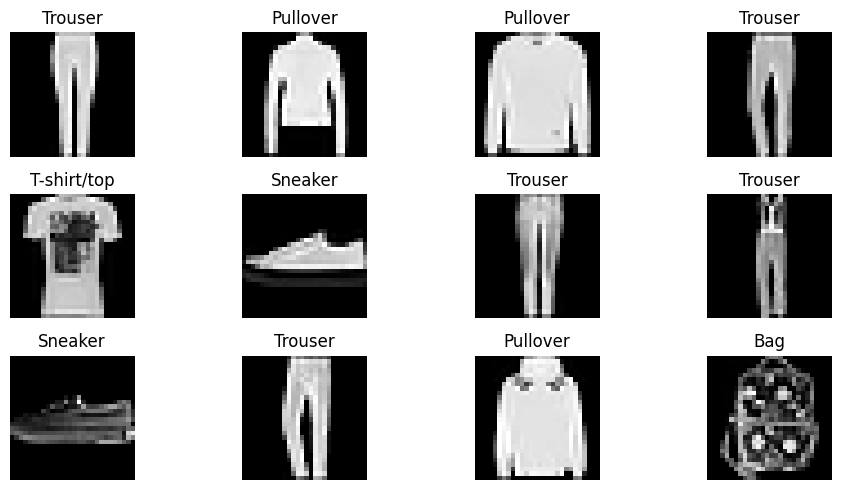

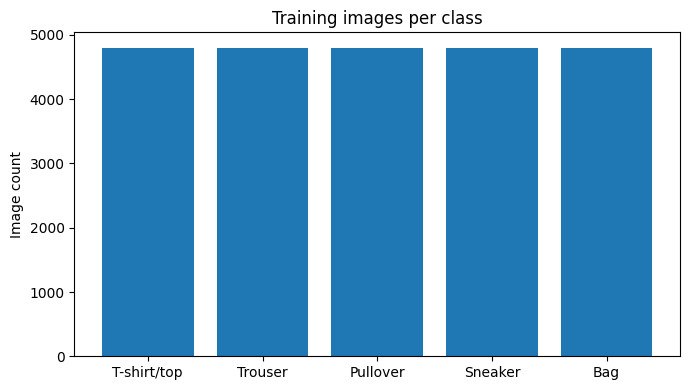

In [4]:
plt.figure(figsize=(10, 5))
for i in range(12):
    plt.subplot(3, 4, i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.bar(class_names, np.bincount(y_train, minlength=4))
plt.title("Training images per class")
plt.ylabel("Image count")
plt.tight_layout()
plt.show()

## 4. Normalize images and prepare CNN inputs

In [5]:
# Normalize grayscale pixels to [0, 1] and add channel dimension
x_train_cnn = x_train.astype("float32")[..., None] / 255.0
x_val_cnn = x_val.astype("float32")[..., None] / 255.0
x_test_cnn = x_test.astype("float32")[..., None] / 255.0

print(x_train_cnn.shape, x_val_cnn.shape, x_test_cnn.shape)

(24000, 28, 28, 1) (3000, 28, 28, 1) (3000, 28, 28, 1)


## 5. Model A – compact CNN trained from scratch

In [9]:
augmentation = keras.Sequential([
    layers.RandomRotation(0.04),
    layers.RandomTranslation(0.05, 0.05)
], name="augmentation")

def build_cnn():
    inputs = keras.Input(shape=(28, 28, 1))
    x = augmentation(inputs)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(5, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="Fashion_CNN")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

cnn_model = build_cnn()
cnn_model.summary()

Model: "Fashion_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,637 (397.02 KB)

 Trainable params: 101,445 (396.27 KB)

 Non-trainable params: 192 (768.00 B)

In [10]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)
]
start = time.time()

history_cnn = cnn_model.fit(
    x_train_cnn, y_train,
    validation_data=(x_val_cnn, y_val),
    epochs=12,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

cnn_time = time.time() - start
print(f"CNN training time: {cnn_time/60:.2f} minutes")

Epoch 1/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 62s 297ms/step - accuracy: 0.9122 - loss: 0.2772 - val_accuracy: 0.2000 - val_loss: 1.9796 - learning_rate: 0.0010
Epoch 2/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 56s 298ms/step - accuracy: 0.9647 - loss: 0.1150 - val_accuracy: 0.3550 - val_loss: 1.9386 - learning_rate: 0.0010
Epoch 3/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 80s 290ms/step - accuracy: 0.9740 - loss: 0.0891 - val_accuracy: 0.9243 - val_loss: 0.2777 - learning_rate: 0.0010
Epoch 4/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 55s 292ms/step - accuracy: 0.9743 - loss: 0.0807 - val_accuracy: 0.9700 - val_loss: 0.0926 - learning_rate: 0.0010
Epoch 5/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 53s 283ms/step - accuracy: 0.9772 - loss: 0.0726 - val_accuracy: 0.9580 - val_loss: 0.1557 - learning_rate: 0.0010
Epoch 6/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 82s 282ms/step - accuracy: 0.9795 - loss: 0.0668 - val_accuracy: 0.9603 - val_loss: 0.1470 - learning_rate: 0.0010
Epoch 7/12
188/188 ━━━━━━━━━━━━━━━━━━━━ 53s 282ms/step - accuracy: 0.9

## 6. Model B – MobileNetV2 transfer learning
Fashion-MNIST grayscale images are repeated across three channels, resized to 96×96 and passed through MobileNetV2 preprocessing.

In [11]:
IMG_SIZE = 96
BATCH_SIZE = 128

def make_mobilenet_ds(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(12000, seed=SEED)
    ds = ds.batch(BATCH_SIZE)
    def preprocess(image, label):
        image = tf.cast(image, tf.float32) / 255.0
        image = tf.expand_dims(image, axis=-1)
        image = tf.image.grayscale_to_rgb(image)
        image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
        image = keras.applications.mobilenet_v2.preprocess_input(image * 255.0)
        return image, tf.cast(label, tf.int32)
    return ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

train_ds = make_mobilenet_ds(x_train, y_train, training=True)
val_ds = make_mobilenet_ds(x_val, y_val)
test_ds = make_mobilenet_ds(x_test, y_test)

In [15]:
base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(28, 28, 1))
x = augmentation(inputs)
x = layers.Resizing(IMG_SIZE, IMG_SIZE)(x)
x = layers.Concatenate()([x, x, x])
x = layers.Lambda(lambda z: keras.applications.mobilenet_v2.preprocess_input(z * 255.0))(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(5, activation="softmax")(x)

transfer_model = keras.Model(inputs, outputs, name="Fashion_MobileNetV2")
transfer_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
transfer_model.summary()

Model: "Fashion_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 28, 28, 1) │          0 │ input_layer_9[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing_1          │ (None, 96, 96, 1) │          0 │ augmentation[2][… │
│ (Resizing)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 96, 96, 3) │          0 │ resizing_1[0][0], │
│ (Concatenate)       │                   │            │ resizing_1[0][0], │
│                     │                   │            │ resizing_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 96, 96, 3) │          0 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_96 │ (None, 3, 3,      │  2,257,984 │ lambda_1[0][0]    │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 5)         │      6,405 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
print("MobileNetV2 output:", transfer_model.output_shape)
print("Number of classes:", len(np.unique(y_train)))
print("Training labels:", np.unique(y_train))

MobileNetV2 output: (None, 5)
Number of classes: 5
Training labels: [0 1 2 3 4]


In [17]:
start = time.time()
history_transfer = transfer_model.fit(
    x_train_cnn, y_train, validation_data=(x_val_cnn, y_val),
    epochs=8, batch_size=128, callbacks=callbacks, verbose=1
)
feature_time = time.time() - start
print(f"Feature-extraction training time: {feature_time/60:.2f} minutes")

Epoch 1/8
188/188 ━━━━━━━━━━━━━━━━━━━━ 221s 1s/step - accuracy: 0.9053 - loss: 0.2779 - val_accuracy: 0.9640 - val_loss: 0.1193 - learning_rate: 0.0010
Epoch 2/8
188/188 ━━━━━━━━━━━━━━━━━━━━ 230s 1s/step - accuracy: 0.9649 - loss: 0.1105 - val_accuracy: 0.9723 - val_loss: 0.0975 - learning_rate: 0.0010
Epoch 3/8
188/188 ━━━━━━━━━━━━━━━━━━━━ 243s 1s/step - accuracy: 0.9694 - loss: 0.0949 - val_accuracy: 0.9750 - val_loss: 0.0930 - learning_rate: 5.0000e-04
Feature-extraction training time: 11.57 minutes


## 7. Fine-tune the final MobileNetV2 layers

In [18]:
base_model.trainable = True
for layer in base_model.layers[:-25]:
    layer.trainable = False

transfer_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_finetune = transfer_model.fit(
    x_train_cnn, y_train, validation_data=(x_val_cnn, y_val),
    epochs=4, batch_size=128, callbacks=callbacks, verbose=1
)
fine_tune_time = time.time() - start
print(f"Fine-tuning time: {fine_tune_time/60:.2f} minutes")

Epoch 1/4
188/188 ━━━━━━━━━━━━━━━━━━━━ 329s 2s/step - accuracy: 0.8901 - loss: 0.3232 - val_accuracy: 0.9767 - val_loss: 0.0953 - learning_rate: 1.0000e-05
Epoch 2/4
188/188 ━━━━━━━━━━━━━━━━━━━━ 321s 2s/step - accuracy: 0.9610 - loss: 0.1232 - val_accuracy: 0.9767 - val_loss: 0.0917 - learning_rate: 1.0000e-05
Epoch 3/4
188/188 ━━━━━━━━━━━━━━━━━━━━ 321s 2s/step - accuracy: 0.9666 - loss: 0.1075 - val_accuracy: 0.9763 - val_loss: 0.0910 - learning_rate: 5.0000e-06
Fine-tuning time: 16.18 minutes


## 8. Evaluate both models on the same held-out test set

In [19]:
def evaluate_model(model, x, y, name):
    probs = model.predict(x, batch_size=128, verbose=1)
    pred = np.argmax(probs, axis=1)
    p, r, f, _ = precision_recall_fscore_support(
        y, pred, average="weighted", zero_division=0
    )
    metrics = {"Model": name, "Accuracy": accuracy_score(y, pred),
               "Precision (weighted)": p, "Recall (weighted)": r, "F1-score (weighted)": f}
    return metrics, pred

cnn_metrics, cnn_pred = evaluate_model(cnn_model, x_test_cnn, y_test, "CNN from scratch")
transfer_metrics, transfer_pred = evaluate_model(transfer_model, x_test_cnn, y_test, "MobileNetV2 transfer learning")
results = pd.DataFrame([cnn_metrics, transfer_metrics])
display(results.round(4))

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,CNN from scratch,0.9820,0.9821,0.9820,0.9820
1,MobileNetV2 transfer learning,0.9753,0.9754,0.9753,0.9753


## 9. Classification reports and confusion matrices

CNN FROM SCRATCH
              precision    recall  f1-score   support

 T-shirt/top       0.95      0.97      0.96       600
     Trouser       0.99      0.99      0.99       600
    Pullover       0.98      0.96      0.97       600
     Sneaker       1.00      0.99      1.00       600
         Bag       0.98      0.99      0.98       600

    accuracy                           0.98      3000
   macro avg       0.98      0.98      0.98      3000
weighted avg       0.98      0.98      0.98      3000

MOBILENETV2 TRANSFER LEARNING
              precision    recall  f1-score   support

 T-shirt/top       0.97      0.95      0.96       600
     Trouser       0.99      0.99      0.99       600
    Pullover       0.95      0.97      0.96       600
     Sneaker       0.99      1.00      1.00       600
         Bag       0.97      0.97      0.97       600

    accuracy                           0.98      3000
   macro avg       0.98      0.98      0.98      3000
weighted avg       0.98      0

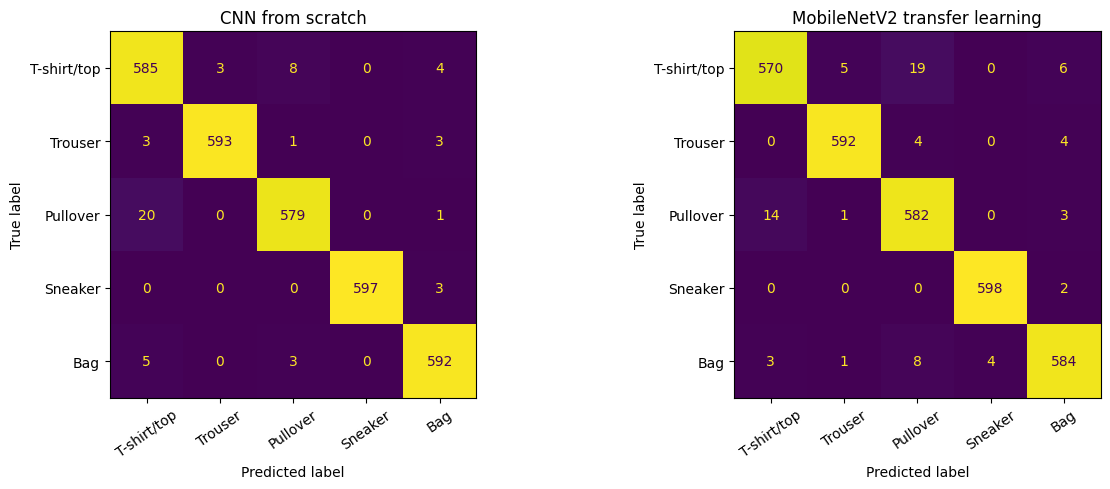

In [20]:
print("CNN FROM SCRATCH")
print(classification_report(y_test, cnn_pred, target_names=class_names, zero_division=0))
print("MOBILENETV2 TRANSFER LEARNING")
print(classification_report(y_test, transfer_pred, target_names=class_names, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, cnn_pred, display_labels=class_names,
                                        xticks_rotation=35, ax=axes[0], colorbar=False)
axes[0].set_title("CNN from scratch")
ConfusionMatrixDisplay.from_predictions(y_test, transfer_pred, display_labels=class_names,
                                        xticks_rotation=35, ax=axes[1], colorbar=False)
axes[1].set_title("MobileNetV2 transfer learning")
plt.tight_layout()
plt.show()

## 10. Training curves

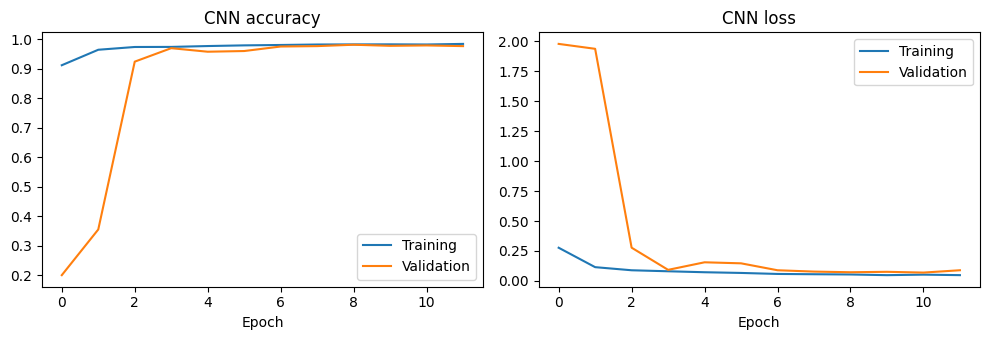

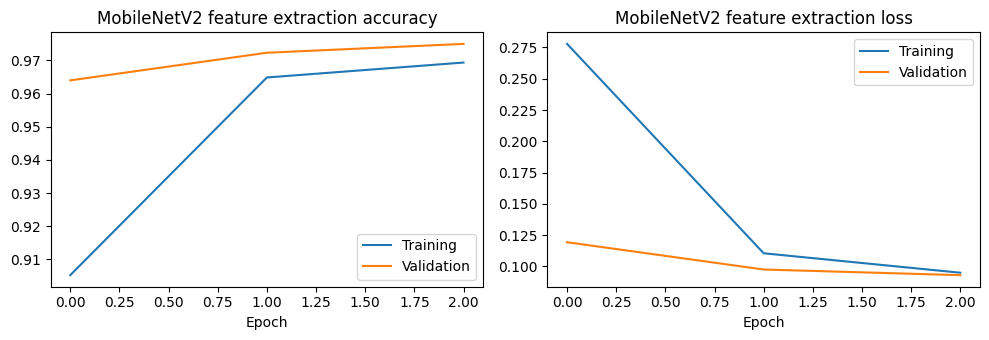

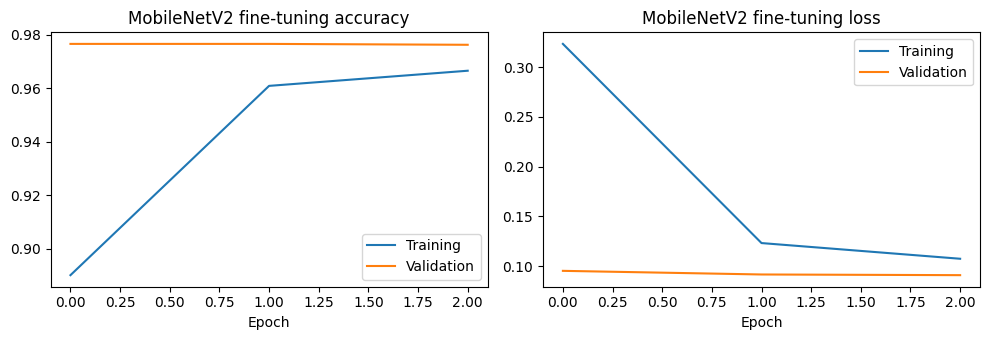

In [21]:
def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(history.history["accuracy"], label="Training")
    ax[0].plot(history.history["val_accuracy"], label="Validation")
    ax[0].set_title(title + " accuracy")
    ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(history.history["loss"], label="Training")
    ax[1].plot(history.history["val_loss"], label="Validation")
    ax[1].set_title(title + " loss")
    ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history_cnn, "CNN")
plot_history(history_transfer, "MobileNetV2 feature extraction")
plot_history(history_finetune, "MobileNetV2 fine-tuning")

## 11. Display sample predictions

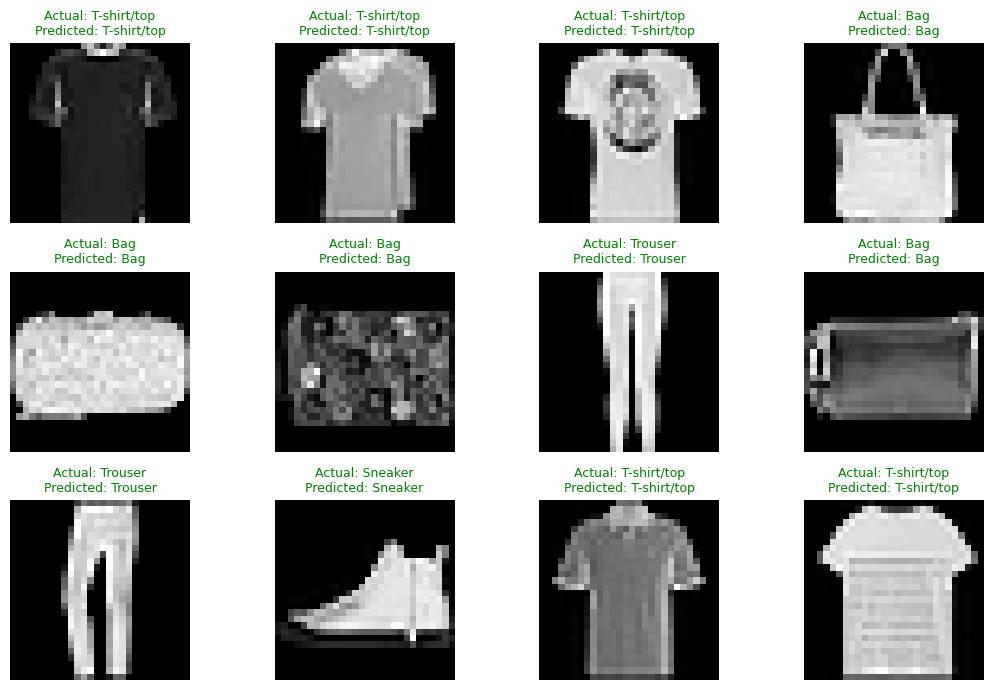

In [22]:
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(len(x_test), 12, replace=False)
plt.figure(figsize=(11, 7))
for j, idx in enumerate(sample_ids):
    plt.subplot(3, 4, j+1)
    plt.imshow(x_test[idx], cmap="gray")
    actual, predicted = class_names[y_test[idx]], class_names[transfer_pred[idx]]
    plt.title(f"Actual: {actual}\nPredicted: {predicted}",
              color="green" if actual == predicted else "red", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 12. Save results and trained models

In [23]:
results.to_csv("fashion_transfer_learning_results.csv", index=False)
cnn_model.save("fashion_cnn_from_scratch.keras")
transfer_model.save("fashion_mobilenetv2.keras")
print("Saved results CSV and both trained models.")

Saved results CSV and both trained models.


## Result
The experiment compares a CNN trained from scratch with MobileNetV2 transfer learning on a balanced, 30,000-image subset of Fashion-MNIST. The measured metrics, classification reports and confusion matrices generated above form the experimental results.

## Conclusion
A compact CNN and a pre-trained MobileNetV2 model were implemented for four-category clothing image classification. The transfer-learning approach reuses image features learned from ImageNet, while fine-tuning adapts selected layers to the Fashion-MNIST task. The final comparison is based on measured test accuracy, weighted precision, recall, F1-score, confusion matrices and training time.

## References
1. Xiao, H., Rasul, K., & Vollgraf, R. (2017). Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms.
2. Sandler, M. et al. (2018). MobileNetV2: Inverted Residuals and Linear Bottlenecks.
3. TensorFlow/Keras documentation: https://www.tensorflow.org/